# Tugas Lab - Klasterisasi Data Nasabah Kartu Kredit

Dataset yang digunakan adalah `dataset/CC_Customer_Dataset.csv`.

## 1. Load dan Inspeksi Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('../dataset/CC_Customer_Dataset.csv')
print('Ukuran dataset:', df.shape)
df.head()

Ukuran dataset: (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Sl_No,660.0,330.500000,190.669872,1.0,165.75,330.5,495.25,660.0
Customer Key,660.0,55141.443939,25627.772200,11265.0,33825.25,53874.5,77202.50,99843.0
Avg_Credit_Limit,660.0,34574.242424,37625.487804,3000.0,10000.00,18000.0,48000.00,200000.0
Total_Credit_Cards,660.0,4.706061,2.167835,1.0,3.00,5.0,6.00,10.0
Total_visits_bank,660.0,2.403030,1.631813,0.0,1.00,2.0,4.00,5.0
Total_visits_online,660.0,2.606061,2.935724,0.0,1.00,2.0,4.00,15.0
Total_calls_made,660.0,3.583333,2.865317,0.0,1.00,3.0,5.00,10.0


In [5]:
print('Missing values:', df.isna().sum().sum())
print('Data duplikat:', df.duplicated().sum())

Missing values: 0
Data duplikat: 0


## 2. Scatterplot `Avg_Credit_Limit` vs `Total_Credit_Cards`

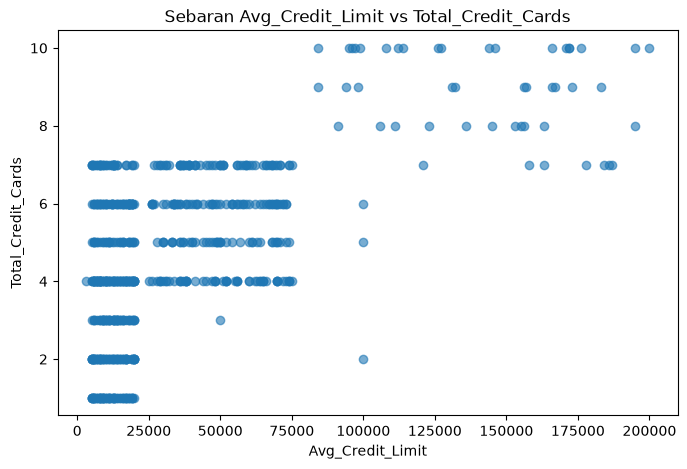

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], alpha=0.6)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Sebaran Avg_Credit_Limit vs Total_Credit_Cards')
plt.show()

**Apakah sebaran data dapat dikatakan linear?** Tidak. `Avg_Credit_Limit` cenderung membentuk beberapa kelompok nilai (pita vertikal), sedangkan `Total_Credit_Cards` menyebar pada rentang 1-10 kartu. Tidak terlihat pola garis lurus yang konsisten antara kedua variabel, sehingga hubungan keduanya tidak linear dan klasterisasi berbasis jarak perlu dilakukan setelah standardisasi.

## 3. Klasterisasi K-Means pada Dua Variabel

### 3.1 Standardisasi

In [7]:
X2 = df[['Avg_Credit_Limit', 'Total_Credit_Cards']]

scaler2 = StandardScaler()
X2_scaled = scaler2.fit_transform(X2)

print('Rata-rata setelah scaling:', X2_scaled.mean(axis=0))
print('Standar deviasi setelah scaling:', X2_scaled.std(axis=0))

Rata-rata setelah scaling: [8.61263922e-17 4.30631961e-17]
Standar deviasi setelah scaling: [1. 1.]


### 3.2 Menentukan k Terbaik dengan Elbow Method

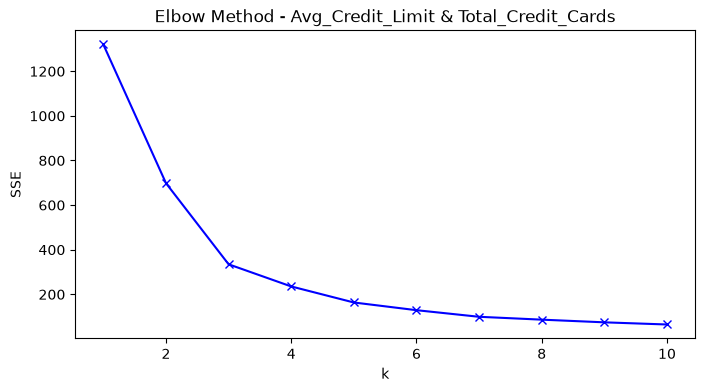

k=1: SSE=1320.000
k=2: SSE=698.293
k=3: SSE=334.724
k=4: SSE=235.393
k=5: SSE=163.472
k=6: SSE=128.964
k=7: SSE=99.370
k=8: SSE=86.534
k=9: SSE=74.530
k=10: SSE=64.826


In [8]:
sse2 = []
K = range(1, 11)

for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X2_scaled)
    sse2.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse2, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Elbow Method - Avg_Credit_Limit & Total_Credit_Cards')
plt.show()

for k, nilai in zip(K, sse2):
    print(f'k={k}: SSE={nilai:.3f}')

**Analisis:** Penurunan SSE terbesar terjadi dari `k=1` ke `k=2` (1320,00 menjadi 698,29) dan dari `k=2` ke `k=3` (698,29 menjadi 334,72). Setelah `k=3`, penurunan SSE jauh lebih landai (235,39; 163,47; 128,96; ...). Titik "elbow" berada pada **k=3**, sehingga tiga cluster dipilih untuk merepresentasikan kelompok nasabah berdasarkan batas kredit dan jumlah kartu.

### 3.3 Hasil Klasterisasi K-Means

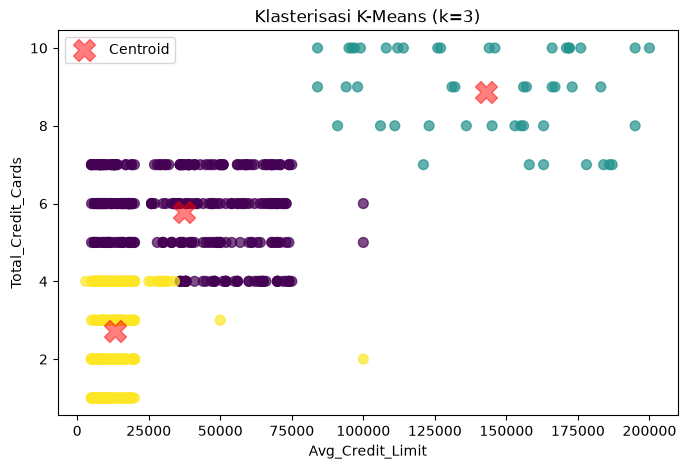

In [9]:
kmeans_cc = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_cc = kmeans_cc.fit_predict(X2_scaled)

centers_cc = scaler2.inverse_transform(kmeans_cc.cluster_centers_)

plt.figure(figsize=(8, 5))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'],
            c=cluster_cc, cmap='viridis', alpha=0.7, s=50)
plt.scatter(centers_cc[:, 0], centers_cc[:, 1],
            c='red', s=250, alpha=0.5, marker='X', label='Centroid')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Klasterisasi K-Means (k=3)')
plt.legend()
plt.show()

In [10]:
# Profil rata-rata setiap cluster
df_profile = df[['Avg_Credit_Limit', 'Total_Credit_Cards']].copy()
df_profile['Cluster'] = cluster_cc
print(df_profile.groupby('Cluster').mean())
print('\nJumlah anggota setiap cluster:')
print(df_profile['Cluster'].value_counts().sort_index())

         Avg_Credit_Limit  Total_Credit_Cards
Cluster                                      
0            37160.606061            5.787879
1           142750.000000            8.875000
2            13134.751773            2.730496

Jumlah anggota setiap cluster:
Cluster
0    330
1     48
2    282
Name: count, dtype: int64


## 4. Klasterisasi DBSCAN dengan Seluruh Variabel

Kolom `Sl_No` dan `Customer Key` adalah identitas, bukan fitur perilaku nasabah, sehingga tidak digunakan. Lima variabel numerik yang tersisa distandardisasi agar skala `Avg_Credit_Limit` tidak mendominasi perhitungan jarak.

In [11]:
features = ['Avg_Credit_Limit', 'Total_Credit_Cards',
            'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']

X_all = df[features]

scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all)

print('Jumlah fitur:', X_all_scaled.shape[1])
print('Jumlah data:', X_all_scaled.shape[0])

Jumlah fitur: 5
Jumlah data: 660


In [12]:
dbscan_cc = DBSCAN(eps=1.0, min_samples=5)
cluster_db = dbscan_cc.fit_predict(X_all_scaled)

label_counts = pd.Series(cluster_db).value_counts().sort_index()
print('Distribusi label (-1 = noise):')
print(label_counts)

Distribusi label (-1 = noise):
-1     18
 0    608
 1     34
Name: count, dtype: int64


Parameter `eps=1.0` dan `min_samples=5` dipilih pada skala data yang telah distandardisasi. Nilai tersebut menghasilkan dua cluster utama dan hanya sekitar 2,7% data yang ditandai sebagai noise.

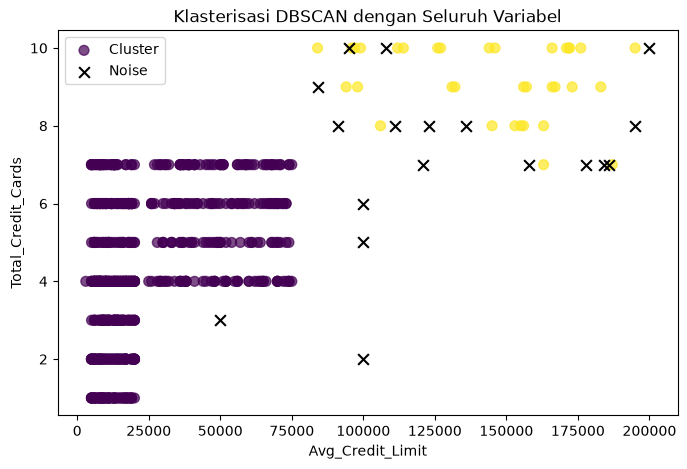

In [13]:
plt.figure(figsize=(8, 5))

# Data non-noise
mask = cluster_db != -1
plt.scatter(df.loc[mask, 'Avg_Credit_Limit'], df.loc[mask, 'Total_Credit_Cards'],
            c=cluster_db[mask], cmap='viridis', alpha=0.7, s=50, label='Cluster')

# Noise
plt.scatter(df.loc[~mask, 'Avg_Credit_Limit'], df.loc[~mask, 'Total_Credit_Cards'],
            c='black', marker='x', s=60, label='Noise')

plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Klasterisasi DBSCAN dengan Seluruh Variabel')
plt.legend()
plt.show()

In [14]:
# Profil rata-rata setiap cluster (tanpa noise)
df_profile_db = X_all.copy()
df_profile_db['Cluster'] = cluster_db
print(df_profile_db[df_profile_db['Cluster'] != -1].groupby('Cluster').mean())

         Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  \
Cluster                                                            
0            25685.855263            4.381579           2.557566   
1           143588.235294            9.176471           0.735294   

         Total_visits_online  Total_calls_made  
Cluster                                         
0                   1.914474          3.786184  
1                  10.235294          1.147059  


## 5. Elbow Method pada Seluruh Variabel

DBSCAN tidak menggunakan parameter jumlah cluster `k`, sehingga elbow method diterapkan pada K-Means yang dibangun dari seluruh variabel sebagai pembanding. Hasil ini menunjukkan berapa banyak cluster yang wajar dibentuk dari data yang sama.

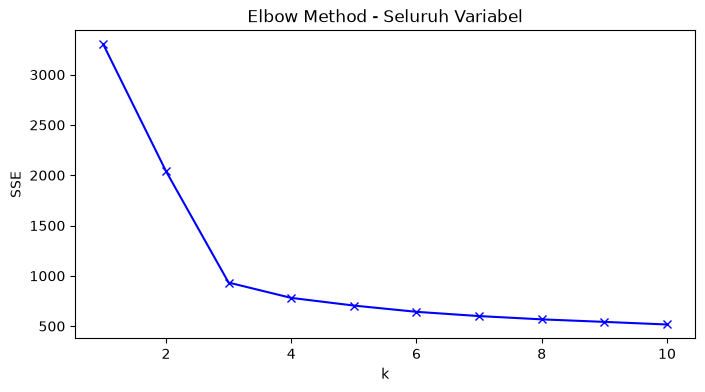

k=1: SSE=3300.000
k=2: SSE=2040.990
k=3: SSE=933.044
k=4: SSE=780.774
k=5: SSE=704.476
k=6: SSE=642.274
k=7: SSE=599.925
k=8: SSE=567.328
k=9: SSE=542.253
k=10: SSE=516.242


In [15]:
sse_all = []
K = range(1, 11)

for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_all_scaled)
    sse_all.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse_all, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Elbow Method - Seluruh Variabel')
plt.show()

for k, nilai in zip(K, sse_all):
    print(f'k={k}: SSE={nilai:.3f}')

**Analisis:** SSE turun tajam dari `k=1` ke `k=2` (3300,00 menjadi 2040,99) dan dari `k=2` ke `k=3` (2040,99 menjadi 933,04). Setelah `k=3`, penurunan menjadi lebih landai (780,77; 704,48; 642,27; ...). Titik elbow berada pada **k=3**, sehingga tiga cluster dinilai paling sesuai untuk struktur data nasabah secara keseluruhan. Jumlah ini konsisten dengan hasil elbow pada dua variabel sebelumnya.

## 6. Evaluasi Model DBSCAN

In [16]:
sil = silhouette_score(X_all_scaled, cluster_db)
dbi = davies_bouldin_score(X_all_scaled, cluster_db)

print(f'Silhouette Score (termasuk noise): {sil:.4f}')
print(f'Davies-Bouldin Index (termasuk noise): {dbi:.4f}')

Silhouette Score (termasuk noise): 0.5212
Davies-Bouldin Index (termasuk noise): 2.1613


Label noise (`-1`) diperlakukan sebagai satu kelompok pada perhitungan di atas. Untuk melihat kualitas cluster yang terbentuk tanpa pengaruh noise, metrik juga dihitung hanya pada data non-noise.

In [17]:
sil_clean = silhouette_score(X_all_scaled[mask], cluster_db[mask])
dbi_clean = davies_bouldin_score(X_all_scaled[mask], cluster_db[mask])

print(f'Silhouette Score (tanpa noise): {sil_clean:.4f}')
print(f'Davies-Bouldin Index (tanpa noise): {dbi_clean:.4f}')

noise_pct = (~mask).sum() / len(cluster_db) * 100
print(f'Persentase noise: {noise_pct:.2f}%')

Silhouette Score (tanpa noise): 0.5680
Davies-Bouldin Index (tanpa noise): 0.6015
Persentase noise: 2.73%


**Interpretasi:** Dengan noise disertakan, silhouette score sekitar **0,52** dan DBI sekitar **2,16**. Setelah noise dikeluarkan, silhouette score naik menjadi sekitar **0,57** dan DBI turun menjadi sekitar **0,60**, yang menunjukkan bahwa cluster inti terpisah cukup baik. DBI yang lebih rendah (semakin baik) dan silhouette yang lebih tinggi (semakin baik) mengindikasikan kualitas klaster yang wajar. DBSCAN juga berhasil menandai sekitar **2,7%** data sebagai noise, yaitu nasabah dengan perilaku yang menyimpang dari kepadatan cluster utama.